In [1]:
using Pkg
Pkg.activate("path/to/project")
using MajoranaPropagation
using Revise
using PauliPropagation
using Plots
using LaTeXStrings
using Measures

  Activating project at `c:\Users\jugro\Desktop\8Sem_ETH\Research Project\Simulations\path\to\project`


# Testing

In this file, we want to test the most important observables and see if their behaviour matches out predictions. For this, we are considering fock states and superpositions of fock states.

First, we consider basic fermionic states and determine simple expectation values. Then, we take a closer look at a 2x4 Grid with periodic boundary conditions (cube) and show that the observables behave correctly.

In the end, we consider the Fermi-Hubbard dynamics on the 2x4 Grid and complete various runtime simulations of $n_{doublon}$.




## $n_{\uparrow}$, $n_{\downarrow}$ and $n_{\uparrow}n_{\downarrow}$ with fermionic states
First, we start with the simplest case: One occupied state

In [2]:
#observables
N_spinful_sites = 1
obs_nup= VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nup, 1))
obs_ndn= VectorMajoranaSum(MajoranaSum(N_spinful_sites, :ndn, 1))
obs_nupndn= VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 1))

#initial states
initial_state1 = FockState(N_spinful_sites, [1],[])
initial_state2 = FockState(N_spinful_sites, [],[1])
initial_state3 = FockState(N_spinful_sites, [1], [1])
@show initial_state1
@show initial_state2

@show initial_state3
@show overlapwithfock(obs_nup, initial_state1) #should be 1
@show overlapwithfock(obs_nup, initial_state2) #should be 0
@show overlapwithfock(obs_ndn, initial_state2) #should be 1
@show overlapwithfock(obs_ndn, initial_state1) #should be 0
@show overlapwithfock(obs_nupndn, initial_state3); #should be 1
@show overlapwithfock(obs_nupndn, initial_state1); #should be 0
@show overlapwithfock(obs_nupndn, initial_state2); #should be 0

initial_state1 = Fock state with 1 fermions at positions
    ↑: 1
    ↓: 

initial_state2 = Fock state with 1 fermions at positions
    ↑: 
    ↓: 1

initial_state3 = Fock state with 2 fermions at positions
    ↑: 1
    ↓: 1

overlapwithfock(obs_nup, initial_state1) = 1.0
overlapwithfock(obs_nup, initial_state2) = 0.0
overlapwithfock(obs_ndn, initial_state2) = 1.0
overlapwithfock(obs_ndn, initial_state1) = 0.0
overlapwithfock(obs_nupndn, initial_state3) = 1.0
overlapwithfock(obs_nupndn, initial_state1) = 0.0
overlapwithfock(obs_nupndn, initial_state2) = 0.0


## $n_{\uparrow}$, $n_{\downarrow}$ and $n_{\uparrow}n_{\downarrow}$ with superpositions

Again, we focus on the simplest cases:

In [4]:
initial_state_superposition1 = [initial_state1, initial_state2]
initial_state_superposition2= [initial_state1, initial_state3]
coeffs=[1/sqrt(2), 1/sqrt(2)]
@show initial_state_superposition1
@show initial_state_superposition2
@show overlapwithfock(obs_nup, initial_state_superposition1, coeffs) #should be 1/2
@show overlapwithfock(obs_ndn, initial_state_superposition1, coeffs) #should be 1/2
@show overlapwithfock(obs_nupndn, initial_state_superposition1, coeffs) #should be 0
@show overlapwithfock(obs_nupndn, initial_state_superposition2, coeffs); #should be 1/2


initial_state_superposition1 = FockState{UInt8}[Fock state with 1 fermions at positions
    ↑: 1
    ↓: 
, Fock state with 1 fermions at positions
    ↑: 
    ↓: 1
]
initial_state_superposition2 = FockState{UInt8}[Fock state with 1 fermions at positions
    ↑: 1
    ↓: 
, Fock state with 2 fermions at positions
    ↑: 1
    ↓: 1
]
overlapwithfock(obs_nup, initial_state_superposition1, coeffs) = 0.49999999999999983
overlapwithfock(obs_ndn, initial_state_superposition1, coeffs) = 0.4999999999999999
overlapwithfock(obs_nupndn, initial_state_superposition1, coeffs) = 0.0
overlapwithfock(obs_nupndn, initial_state_superposition2, coeffs) = 0.4999999999999999


Next we consider the the case of 2 fermions and the superposition of $\ket{\uparrow \downarrow}$ and $\ket{\downarrow \uparrow}$ : $\frac{1}{\sqrt{2}}(\ket{\uparrow \downarrow}+\ket{\downarrow \uparrow})$

In [3]:
N_spinful_sites = 2
initial_state_updn=FockState(N_spinful_sites, [1],[2])
initial_state_dnup=FockState(N_spinful_sites, [2],[1])

initial_state_superposition3=[initial_state_updn, initial_state_dnup]
coeffs=[1/sqrt(2), 1/sqrt(2)]

@show overlapwithfock(obs_nup, initial_state_superposition3, coeffs) #should be 1/2
@show overlapwithfock(obs_ndn, initial_state_superposition3, coeffs) #should be 1/2
@show overlapwithfock(obs_nupndn, initial_state_superposition3, coeffs); #should be 0

overlapwithfock(obs_nup, initial_state_superposition3, coeffs) = 0.4999999999999999
overlapwithfock(obs_ndn, initial_state_superposition3, coeffs) = 0.4999999999999999
overlapwithfock(obs_nupndn, initial_state_superposition3, coeffs) = -2.7755575615628914e-17


# 2x4 Grid

Next, we consider a more complex system: 2x4 Grid with periodic boundary conditions.

First, we show that our single-site observables $n_{\uparrow}, n_{\downarrow}, n_{doublon}^1 = n_{\uparrow}^1 n_{\downarrow}^1$ (index meaning: observable acting on site 1) still work in this topology.

In [5]:
#System
N_x = 2
N_y = 4
N_spinful_sites = N_x * N_y
is_spinful = true

#observables
obs_nup= VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nup, 1))
obs_ndn= VectorMajoranaSum(MajoranaSum(N_spinful_sites, :ndn, 1))
obs_nupndn= VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 1))

#initial states
initial_state1 = FockState(N_spinful_sites, [1],[])
initial_state2 = FockState(N_spinful_sites, [],[1])
initial_state3 = FockState(N_spinful_sites, [1], [1])
initial_state_updn=FockState(N_spinful_sites, [1],[2])
initial_state_dnup=FockState(N_spinful_sites, [2],[1])


@show initial_state3
@show overlapwithfock(obs_nup, initial_state1) #should be 1
@show overlapwithfock(obs_nup, initial_state2) #should be 0
@show overlapwithfock(obs_ndn, initial_state2) #should be 1
@show overlapwithfock(obs_ndn, initial_state1) #should be 0
@show overlapwithfock(obs_nupndn, initial_state3); #should be 1
@show overlapwithfock(obs_nupndn, initial_state1); #should be 0
@show overlapwithfock(obs_nupndn, initial_state2); #should be 0


initial_state3 = Fock state with 2 fermions at positions
    ↑: 1
    ↓: 1

overlapwithfock(obs_nup, initial_state1) = 1.0
overlapwithfock(obs_nup, initial_state2) = 0.0
overlapwithfock(obs_ndn, initial_state2) = 1.0
overlapwithfock(obs_ndn, initial_state1) = 0.0
overlapwithfock(obs_nupndn, initial_state3) = 1.0
overlapwithfock(obs_nupndn, initial_state1) = 0.0
overlapwithfock(obs_nupndn, initial_state2) = 0.0


And also with superpositions

In [6]:
initial_state_superposition1 = [initial_state1, initial_state2]
initial_state_superposition2 = [initial_state1, initial_state3]
initial_state_superposition3 = [initial_state_updn, initial_state_dnup]
coeffs = [1/sqrt(2), 1/sqrt(2)]
@show overlapwithfock(obs_nup, initial_state_superposition1, coeffs) #should be 1/2
@show overlapwithfock(obs_ndn, initial_state_superposition1, coeffs) #should be 1/2
@show overlapwithfock(obs_nupndn, initial_state_superposition1, coeffs) #should be 0
@show overlapwithfock(obs_nupndn, initial_state_superposition2, coeffs); #should be 1/2
@show overlapwithfock(obs_nupndn, initial_state_superposition3, coeffs); #should be 0

overlapwithfock(obs_nup, initial_state_superposition1, coeffs) = 0.49999999999999983
overlapwithfock(obs_ndn, initial_state_superposition1, coeffs) = 0.4999999999999999
overlapwithfock(obs_nupndn, initial_state_superposition1, coeffs) = 0.0
overlapwithfock(obs_nupndn, initial_state_superposition2, coeffs) = 0.4999999999999999
overlapwithfock(obs_nupndn, initial_state_superposition3, coeffs) = -2.7755575615628914e-17


We confirmed that single particle observables behave as expected, but what about multiple-particle observables on our Grid?

Thus, we consider the simplest multiple-particle observable $n_{doublon}^{total}=n_{doublon}^1+n_{doublon}^2$, measuring the total number of doublon on sites 1 and 2.

More complex multiple-particle observables, for example measuring the total number of doublons on all sites, will behave in a similar manner and are thus here not mentioned.

In [7]:
#observables
N_spinful_sites = 2
obs_doubl_init = MajoranaSum(Float64, N_spinful_sites, is_spinful)
for i=1:N_spinful_sites
    add!(obs_doubl_init, :nupndn, i)
end
obs_doubl_init = VectorMajoranaSum(obs_doubl_init)

#initial states
initial_state1 = FockState(N_spinful_sites, [1,2],[1,2])
initial_state2 = FockState(N_spinful_sites, [1,2],[1])
initial_state_updn = FockState(N_spinful_sites, [1],[2])
initial_state_dnup = FockState(N_spinful_sites, [2],[1])

@show overlapwithfock(obs_doubl_init, initial_state1); #should be 2
@show overlapwithfock(obs_doubl_init, initial_state2); #should be 1
@show overlapwithfock(obs_doubl_init, initial_state_updn); #should be 0
@show overlapwithfock(obs_doubl_init, initial_state_dnup); #should be 0

overlapwithfock(obs_doubl_init, initial_state1) = 2.0
overlapwithfock(obs_doubl_init, initial_state2) = 1.0
overlapwithfock(obs_doubl_init, initial_state_updn) = 0.0
overlapwithfock(obs_doubl_init, initial_state_dnup) = 0.0


And again with superpositions

In [8]:
initial_state_superposition1 = [initial_state1, initial_state1]
initial_state_superposition2 = [initial_state1, initial_state2]
initial_state_superposition3 = [initial_state_updn, initial_state_dnup]
coeffs = [1/sqrt(2), 1/sqrt(2)]
@show overlapwithfock(obs_doubl_init, initial_state_superposition1, coeffs) #should be 1 + 1 = 2
@show overlapwithfock(obs_doubl_init, initial_state_superposition2, coeffs) #should be 1 + 1/2 = 3/2
@show overlapwithfock(obs_doubl_init, initial_state_superposition3, coeffs); #should be 0

overlapwithfock(obs_doubl_init, initial_state_superposition1, coeffs) = 1.9999999999999996
overlapwithfock(obs_doubl_init, initial_state_superposition2, coeffs) = 1.4999999999999998
overlapwithfock(obs_doubl_init, initial_state_superposition3, coeffs) = -1.1102230246251565e-16


# Fermi-Hubberd dynamics on the 2x4 Grid

We confirmed the right behaviour of all observables and now ready to implement the desired dynamics on our Grid.

In [9]:
#System
N_x = 2
N_y = 4
N_spinful_sites = N_x * N_y
is_spinful = true
topo = rectangletopology(N_x, N_y,periodic=true)

#Dynamics
t = 1
U = 4.
n_layers = 20
dt = 0.1

min_abs_coeff = 1.e-4
max_unpaired = 4
unpaired_mask = create_unpaired_mask(2 * N_spinful_sites);

circ_single = []
thetas_single = []

#up hoppings 
for (i, j) in topo
    push!(circ_single, FermionicGate(:hopup, [i, j]))
    push!(thetas_single, -t * dt)
end

#down hoppings 
for (i, j) in topo
    push!(circ_single, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single, -t * dt)
end

#on-site repulsion 
for i = 1:N_spinful_sites
    push!(circ_single, FermionicGate(:nupndn, i))
    push!(thetas_single, U * dt)
end

#observables
obs_doubl_init = MajoranaSum(Float64, N_spinful_sites, is_spinful)
for i=1:N_spinful_sites
    add!(obs_doubl_init, :nupndn, i)
end
obs_doubl = VectorMajoranaSum(obs_doubl_init);



In [10]:

#inital states
initial_state11 = FockState(N_spinful_sites, [1,3,4,7],[2,5,6,8])
initial_state12 = FockState(N_spinful_sites, [1,3,4,8],[2,5,6,7])
initial_state13 = FockState(N_spinful_sites, [1,3,6,7],[2,4,5,8])
initial_state14 = FockState(N_spinful_sites, [1,3,6,8],[2,4,5,7])  

initial_state21 = FockState(N_spinful_sites, [1,5,4,7],[2,3,6,8])
initial_state22 = FockState(N_spinful_sites, [1,5,4,8],[2,3,6,7])
initial_state23 = FockState(N_spinful_sites, [1,5,6,7],[2,3,4,8])
initial_state24 = FockState(N_spinful_sites, [1,5,6,8],[2,3,4,7])

initial_state31 = FockState(N_spinful_sites, [2,3,4,7],[1,5,6,8])
initial_state32 = FockState(N_spinful_sites, [2,3,4,8],[1,5,6,7])
initial_state33 = FockState(N_spinful_sites, [2,3,6,7],[1,4,5,8])
initial_state34 = FockState(N_spinful_sites, [2,3,6,8],[1,4,5,7])

initial_state41 = FockState(N_spinful_sites, [2,4,5,7],[1,3,6,8])
initial_state42 = FockState(N_spinful_sites, [2,4,5,8],[1,3,6,7])
initial_state43 = FockState(N_spinful_sites, [2,5,6,7],[1,3,4,8])
initial_state44 = FockState(N_spinful_sites, [2,5,6,8],[1,3,4,7])

initial_state = [initial_state11, initial_state12, initial_state13, initial_state14,
    initial_state21, initial_state22, initial_state23, initial_state24,
    initial_state31, initial_state32, initial_state33, initial_state34,
    initial_state41, initial_state42, initial_state43, initial_state44]
coeffs = [1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4]
;

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 

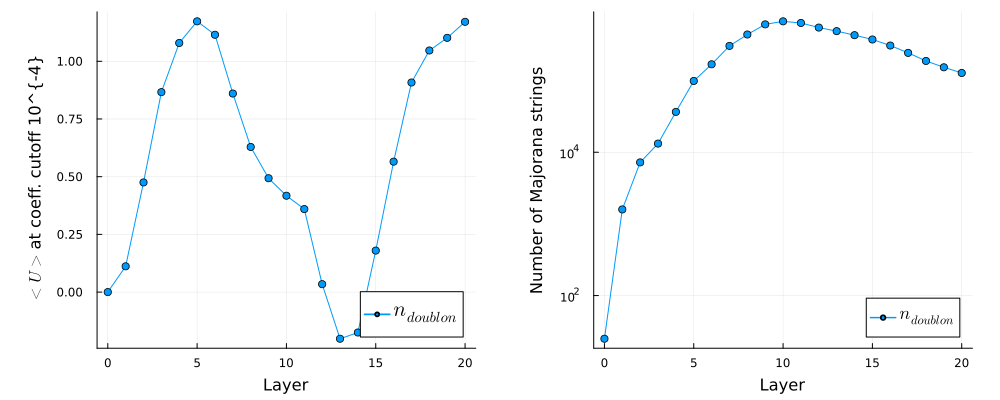

In [11]:
res1 = zeros(n_layers+1)
length1 = zeros(n_layers+1)
res1[1]=overlapwithfock(obs_doubl, initial_state, coeffs)
length1[1] = length(obs_doubl)

#simulation of expectation values for U=2, coefficient truncation at 1.e-4
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single, obs_doubl, thetas_single; min_abs_coeff=min_abs_coeff)
    res1[j+1] = overlapwithfock(obs_doubl, initial_state, coeffs)
    length1[j+1] = length(obs_doubl)
end

ev_plot = plot(xlabel = "Layer", ylabel = L"<U>"*"at coeff. cutoff " *"10^{-4}", legend = :bottomright, legend_font_pointsize = 14)
plot!(ev_plot, 0:n_layers, res1, label=L"n_{doublon}", marker=:circle)

length_plot = plot(xlabel = "Layer",ylabel = "Number of Majorana strings", yscale = :log10, legend = :bottomright,legend_font_pointsize = 12)
plot!(length_plot, 0:n_layers, length1, label=L"n_{doublon}", marker=:circle)

plot(ev_plot, length_plot, layout=(1,2), size=(1000,400),left_margin = 10mm, bottom_margin = 5mm, right_margin = 5mm)

# Tensorproduct expansion

Instead of hardcoding the inital conditions, it would be nice find an algorithm that constructs the initial conditions in the notation of MajoranaPropagation. In our case, we are only interested in pair superpositions such like $(c_{i}c_{j} + c_{j}c_{i})/ \sqrt{2}$, we impose an algorithm that expects a list of pairs and expands the tensor product.

In [40]:
N_x = 2
N_y = 4
N_spinful_sites = N_x * N_y
pair12 = [Dict(1 => :up, 2 => :dn),Dict(1 => :dn, 2 => :up)]
pair35 = [Dict(3 => :up, 5 => :dn),Dict(3 => :dn, 5 => :up)]
pair46 = [Dict(4 => :up, 6 => :dn),Dict(4 => :dn, 6 => :up)]
pair78 = [Dict(7 => :up, 8 => :dn),Dict(7 => :dn, 8 => :up)]


pairs2x4 = [pair12, pair35, pair46, pair78]

function expand_tensor(pairs)
    result = [Dict{Int,Symbol}()]
    @show result
    for pair in pairs
        new_result = []
        for r in result
            for p in pair
                merged = copy(r)
                merge!(merged, p)
                push!(new_result, merged)
            end
        end
        result = new_result
    end

    return result
end

#@show expand_tensor(pairs2x4)

function to_fock(state, N_spinful_sites)
    ups = Int[]
    dns = Int[]

    for (site, spin) in state
        if spin == :up
            push!(ups, site)
        elseif spin == :dn
            push!(dns, site)
        end
    end

    return FockState(N_spinful_sites, sort(ups), sort(dns))
end

states = expand_tensor(pairs2x4)

fock_states = [to_fock(s, N_spinful_sites) for s in states]

@show fock_states[1];

result = [Dict{Int64, Symbol}()]
fock_states[1] = Fock state with 8 fermions at positions
    ↑: 1, 3, 4, 7
    ↓: 2, 5, 6, 8



But how do we know that it works? For this smaller 2x4 Grid, we are able to compute the expansion by hand and we can compare the results from the previous function


In [41]:
#state by hand
initial_state11 = FockState(N_spinful_sites, [1,3,4,7],[2,5,6,8])
initial_state12 = FockState(N_spinful_sites, [1,3,4,8],[2,5,6,7])
initial_state13 = FockState(N_spinful_sites, [1,3,6,7],[2,4,5,8])
initial_state14 = FockState(N_spinful_sites, [1,3,6,8],[2,4,5,7])  

initial_state21 = FockState(N_spinful_sites, [1,5,4,7],[2,3,6,8])
initial_state22 = FockState(N_spinful_sites, [1,5,4,8],[2,3,6,7])
initial_state23 = FockState(N_spinful_sites, [1,5,6,7],[2,3,4,8])
initial_state24 = FockState(N_spinful_sites, [1,5,6,8],[2,3,4,7])

initial_state31 = FockState(N_spinful_sites, [2,3,4,7],[1,5,6,8])
initial_state32 = FockState(N_spinful_sites, [2,3,4,8],[1,5,6,7])
initial_state33 = FockState(N_spinful_sites, [2,3,6,7],[1,4,5,8])
initial_state34 = FockState(N_spinful_sites, [2,3,6,8],[1,4,5,7])

initial_state41 = FockState(N_spinful_sites, [2,4,5,7],[1,3,6,8])
initial_state42 = FockState(N_spinful_sites, [2,4,5,8],[1,3,6,7])
initial_state43 = FockState(N_spinful_sites, [2,5,6,7],[1,3,4,8])
initial_state44 = FockState(N_spinful_sites, [2,5,6,8],[1,3,4,7])

initial_state1 = [initial_state11, initial_state12, initial_state13, initial_state14,
    initial_state21, initial_state22, initial_state23, initial_state24,
    initial_state31, initial_state32, initial_state33, initial_state34,
    initial_state41, initial_state42, initial_state43, initial_state44]

#previously defined state
initial_state2 = fock_states

@show initial_state1[1], initial_state2[1]
@show initial_state1==initial_state2; #should be true, as we defined the same state in two different ways


(initial_state1[1], initial_state2[1]) = (Fock state with 8 fermions at positions
    ↑: 1, 3, 4, 7
    ↓: 2, 5, 6, 8
, Fock state with 8 fermions at positions
    ↑: 1, 3, 4, 7
    ↓: 2, 5, 6, 8
)
initial_state1 == initial_state2 = true


# Runtime considerations of $n_{doublon}$ on the 2x4 Grid

We want to evaluate the runtime of the Fermi-Hubbard dynamics on the 2x4 Grid (with periodic b.c, U=2, max_unpaired=4). In majorana propagation, we propagate the observables in the Heisenberg picture and the runtime therefore independent on the inital state. 

Since runtime depends on the type of truncation (default, truncation after each gate, truncation after each layer) and the coefficient cutoff, we focus on testing the effect on the duration of the simulation while fixing an inital state (here we use a checkerboard with one superposition) and the number of layers

## Type of truncation (cutoff accuracy const.)

In [12]:
min_abs_coeff=1e-12 #playing around with the cutoff to see that the truncation types behave similarly

obs_default = deepcopy(obs_doubl_init)
obs_true = deepcopy(obs_doubl_init)
obs_false = deepcopy(obs_doubl_init)

total_time_default = 0.0
total_time_true = 0.0
total_time_false = 0.0

for j = 1:n_layers 
    total_time_default+= @elapsed propagate!(circ_single, obs_default, thetas_single; min_abs_coeff=min_abs_coeff)
    total_time_true += @elapsed propagate!(circ_single, obs_true, thetas_single; min_abs_coeff=min_abs_coeff,truncate_each_mr=true)
    total_time_false += @elapsed propagate!(circ_single, obs_false, thetas_single; min_abs_coeff=min_abs_coeff,truncate_each_mr=false)
end
println("Total time default: $total_time_default")
println("Total time true: $total_time_true")
println("Total time false: $total_time_false");


Total time default: 2.3812487
Total time true: 2.1687689999999997
Total time false: 2.0417578


## Coefficient cutoff accuracy (using default truncation)

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 

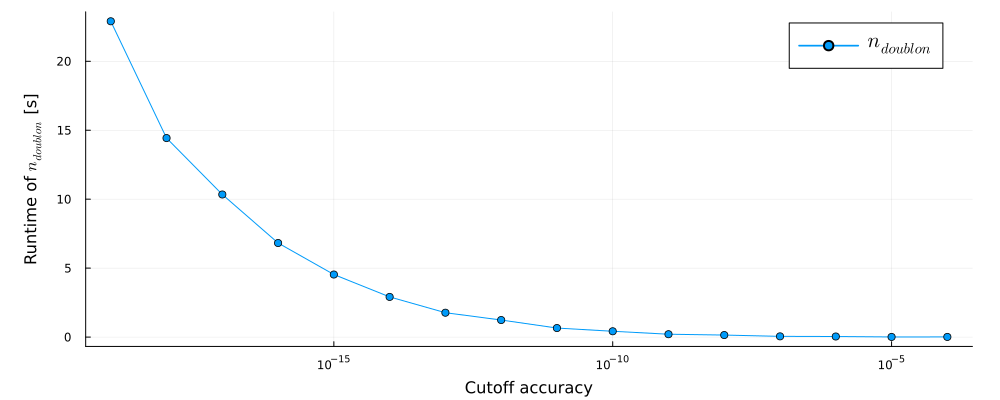

In [15]:
cutoff_coeff = zeros(n_layers+1)
cutoff_coeff[1] = 1e-4
total_time = zeros(n_layers+1)

for j = 1:n_layers
    cutoff_coeff[j+1] = cutoff_coeff[j] * 0.1
end

#inital state, not important here
init_1 = FockState(N_spinful_sites, [1,3,5,7],[2,4,6,8])
init_2 = FockState(N_spinful_sites, [2,3,5,7],[1,4,6,8])
init_superpos_1=[init_1,init_2]

#simulation
for k =1:n_layers+1
    print("$k ")
    obs_doubl = deepcopy(obs_doubl_init) #resetting observable
    for j = 1:n_layers 
        total_time[k] += @elapsed propagate!(circ_single, obs_doubl, thetas_single; min_abs_coeff=cutoff_coeff[k],max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    end
end

#we use log10 on the x-axis to better visualize the differences in runtime for different cutoffs
ev_plot = plot(xlabel = "Cutoff accuracy", ylabel = "Runtime of "* L"n_{doublon}"* " [s]", legend = :topright, legend_font_pointsize = 14,xscale=:log10)
plot!(ev_plot, cutoff_coeff, total_time, label=L"n_{doublon}", marker=:circle,xscale=:log10)

plot(ev_plot, layout=(1,1), size=(1000,400),left_margin = 10mm, bottom_margin = 5mm, right_margin = 5mm)
